### Import libraries

In [8]:
import pandas as pd

In [9]:
import numpy as np

In [10]:
import matplotlib.pyplot as plt

In [11]:
import seaborn as sns

###  Load the DataSet

In [12]:
df = pd.read_csv("Cleaning_Project .csv")

###  Display the dataset

In [13]:
display(df.head()) 

,Name,Age,Salary,Join_Date,Department
0,Pam,25.0,70200.0,1/15/2023,HR
1,Jane,NaN,65000.0,8/1/2022,Finance
2,Alice,22.0,71350.0,5/20/2021,HR
3,Bob,22.0,NaN,1/15/2023,IT
4,Pam,25.0,71250.0,1/15/2023,HR


In [15]:
print(df)

        Name   Age    Salary  Join_Date Department
0        Pam  25.0   70200.0  1/15/2023         HR
1       Jane   NaN   65000.0   8/1/2022    Finance
2      Alice  22.0   71350.0  5/20/2021         HR
3        Bob  22.0       NaN  1/15/2023         IT
4        Pam  25.0   71250.0  1/15/2023         HR
5       Jade  40.0       NaN  1/15/2023    Finance
6     Joanne  25.0  120000.0  1/16/2023         IT
7        Kim  33.0   71568.0  8/30/2021         HR
8        Sam  40.0       NaN   9/5/2022         IT
9        Eli   NaN   80100.0   3/4/2022         HR
10       Joe  22.0   62000.0  10/9/2022    Finance
11      Anna  36.0   72456.0   4/6/2022         HR
12       Dan  43.0       NaN  1/15/2023         HR
13     Susan  46.0   66000.0   5/3/2022    Finance
14    Pamela   NaN   77421.0   4/2/2023         HR
15      Susy  41.0  126001.0   2/2/2023         IT
16      Ruth  30.0   72114.0   9/5/2022         HR
17       Dan  43.0       NaN   5/3/2022         HR
18    Joanne  25.0  125600.0  1

###  Check dataset dimensions

In [16]:
print("Shape:", df.shape)

Shape: (43, 5)


### Check dataset information

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43 entries, 0 to 42
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Name        43 non-null     object 
 1   Age         39 non-null     float64
 2   Salary      36 non-null     float64
 3   Join_Date   43 non-null     object 
 4   Department  43 non-null     object 
dtypes: float64(2), object(3)
memory usage: 1.8+ KB


###  Identify missing values

In [20]:
print("\nMissing Values:")


Missing Values:


In [21]:
print(df.isnull().sum())

Name          0
Age           4
Salary        7
Join_Date     0
Department    0
dtype: int64


###  Identify duplicate rows

In [22]:
print("\nDuplicate Rows:")


Duplicate Rows:


In [26]:
print(df.duplicated().sum())

1


### Handle Missing Values

Analyze missing values

In [28]:
print("Age Mean:",df["Age"].mean())
print("Age Median:",df["Age"].median())

Age Mean: 34.69230769230769
Age Median: 36.0


In [29]:
print("Salary Mean:",df["Salary"].mean())
print("Salary Median:",df["Salary"].median())

Salary Mean: 132729.69444444444
Salary Median: 71841.0


Check salary distribution(calculate the quartiles and IQR:)


In [30]:
Q1 = df["Salary"].quantile(0.25)
Q3 = df["Salary"].quantile(0.75)

IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)


Q1: 66175.0
Q3: 77421.0
IQR: 11246.0


In [31]:

## HANDLE MISSING VALUES

# Create a copy of the original dataset
df_clean = df.copy()

# Fill missing Age values with the median
df_clean["Age"] = df_clean["Age"].fillna(
    df_clean["Age"].median()
)

# Fill missing Salary values with the median
df_clean["Salary"] = df_clean["Salary"].fillna(
    df_clean["Salary"].median()
)

print("Missing values handled successfully!")


Missing values handled successfully!


In [32]:

# Check missing values after cleaning

print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

# Calculate total missing values
print("\nTotal Missing Values:",
      df_clean.isnull().sum().sum())


Missing Values After Cleaning:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64

Total Missing Values: 0


In [35]:

# Compare missing values before and after cleaning

comparison = pd.DataFrame({
    "Before Cleaning": df.isnull().sum(),
    "After Cleaning": df_clean.isnull().sum()
})

display(comparison)


,Before Cleaning,After Cleaning
Name,0,0
Age,4,0
Salary,7,0
Join_Date,0,0
Department,0,0


In [36]:
# Check duplicate rows
print("Duplicate Rows:", df_clean.duplicated().sum())

Duplicate Rows: 1


In [37]:
# Display all duplicate records
display(df_clean[df_clean.duplicated(keep=False)])

,Name,Age,Salary,Join_Date,Department
8,Sam,40.0,71841.0,9/5/2022,IT
31,Sam,40.0,71841.0,9/5/2022,IT


In [38]:
# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Reset index after removing duplicates
df_clean = df_clean.reset_index(drop=True)

print("Duplicate rows removed successfully!")
print("Dataset Shape:", df_clean.shape)

Duplicate rows removed successfully!
Dataset Shape: (42, 5)


In [39]:
# Remove extra spaces from Name and Department columns
df_clean["Name"] = df_clean["Name"].str.strip()
df_clean["Department"] = df_clean["Department"].str.strip()

print("Extra spaces removed successfully!")

Extra spaces removed successfully!


In [40]:
# Convert text values into lowercase
df_clean["Name"] = df_clean["Name"].str.lower()
df_clean["Department"] = df_clean["Department"].str.lower()

print("Text converted to lowercase successfully!")

Text converted to lowercase successfully!


In [41]:
# Display cleaned data
display(df_clean.head())

# Check duplicates
print("Duplicates After Cleaning:", df_clean.duplicated().sum())

# Check dataset shape
print("Dataset Shape:", df_clean.shape)

# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum())

,Name,Age,Salary,Join_Date,Department
0,pam,25.0,70200.0,1/15/2023,hr
1,jane,36.0,65000.0,8/1/2022,finance
2,alice,22.0,71350.0,5/20/2021,hr
3,bob,22.0,71841.0,1/15/2023,it
4,pam,25.0,71250.0,1/15/2023,hr


Duplicates After Cleaning: 0
Dataset Shape: (42, 5)
Missing Values:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
dtype: int64


In [42]:
# Calculate lower and upper boundaries
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: 49306.0
Upper Bound: 94290.0


In [43]:
# Identify potential salary outliers
salary_outliers = df_clean[
    (df_clean["Salary"] < lower_bound) |
    (df_clean["Salary"] > upper_bound)
]

display(salary_outliers)

,Name,Age,Salary,Join_Date,Department
6,joanne,25.0,120000.0,1/16/2023,it
15,susy,41.0,126001.0,2/2/2023,it
18,joanne,25.0,125600.0,1/16/2023,it
21,norma,51.0,921000.0,2/4/2021,it
28,jenny,36.0,801423.0,9/15/2021,it
41,kim,33.0,546222.0,8/30/2021,hr


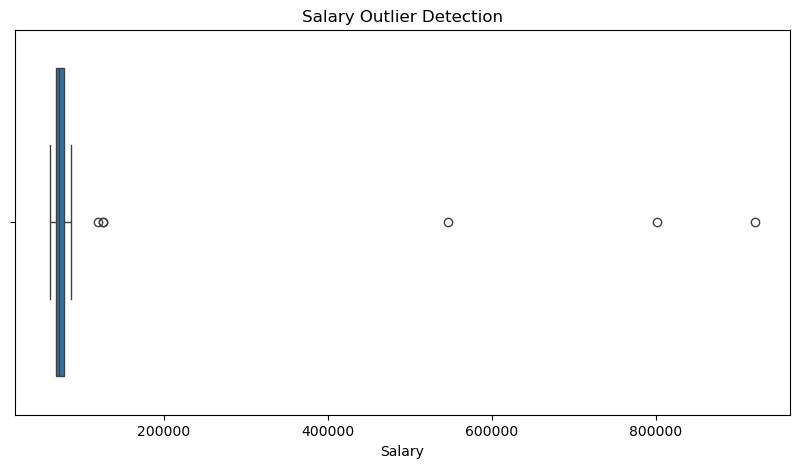

In [44]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df_clean["Salary"])

plt.title("Salary Outlier Detection")
plt.xlabel("Salary")

plt.show()

In [45]:
print("Before Conversion:")
print(df_clean["Join_Date"].dtype)

Before Conversion:
object


In [46]:
# Convert Join_Date column into datetime format
df_clean["Join_Date"] = pd.to_datetime(
    df_clean["Join_Date"],
    errors="coerce"
)

print("Date conversion completed successfully!")

Date conversion completed successfully!


In [47]:
# Check the data type after conversion
print("After Conversion:")
print(df_clean["Join_Date"].dtype)

# Display first five dates
display(df_clean[["Join_Date"]].head())

# Check invalid dates
print("Invalid Dates:", df_clean["Join_Date"].isnull().sum())

After Conversion:
datetime64[ns]


,Join_Date
0,2023-01-15
1,2022-08-01
2,2021-05-20
3,2023-01-15
4,2023-01-15


Invalid Dates: 0


In [48]:
# Convert Department into numerical columns
df_encoded = pd.get_dummies(
    df_clean,
    columns=["Department"],
    dtype=int
)

display(df_encoded.head())

,Name,Age,Salary,Join_Date,Department_finance,Department_hr,Department_it
0,pam,25.0,70200.0,2023-01-15,0,1,0
1,jane,36.0,65000.0,2022-08-01,1,0,0
2,alice,22.0,71350.0,2021-05-20,0,1,0
3,bob,22.0,71841.0,2023-01-15,0,0,1
4,pam,25.0,71250.0,2023-01-15,0,1,0


In [49]:
print("Original Dataset Shape:", df_clean.shape)
print("Encoded Dataset Shape:", df_encoded.shape)

display(df_encoded.head())


Original Dataset Shape: (42, 5)
Encoded Dataset Shape: (42, 7)


,Name,Age,Salary,Join_Date,Department_finance,Department_hr,Department_it
0,pam,25.0,70200.0,2023-01-15,0,1,0
1,jane,36.0,65000.0,2022-08-01,1,0,0
2,alice,22.0,71350.0,2021-05-20,0,1,0
3,bob,22.0,71841.0,2023-01-15,0,0,1
4,pam,25.0,71250.0,2023-01-15,0,1,0


In [50]:
# Save the cleaned dataset
df_clean.to_csv("employee_data_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [51]:
import os

print("File Location:", os.getcwd())

File Location: C:\Users\palla


### Data Visualization

Bar chart: Employee count by department

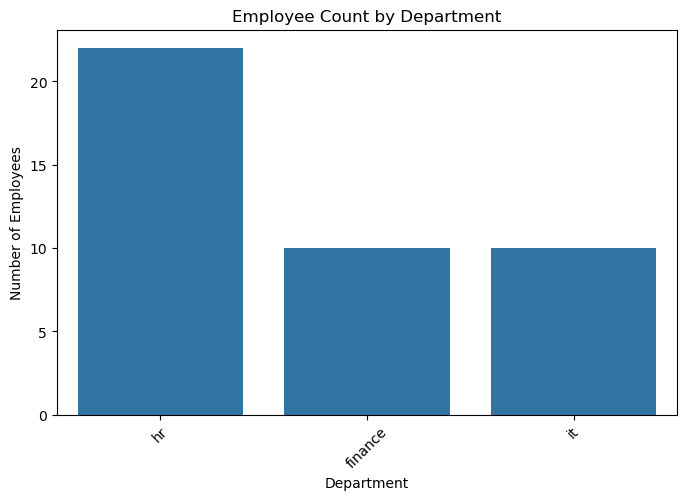

In [52]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean, x="Department")

plt.title("Employee Count by Department")
plt.xlabel("Department")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)

plt.show()

Histogram: Salary distribution

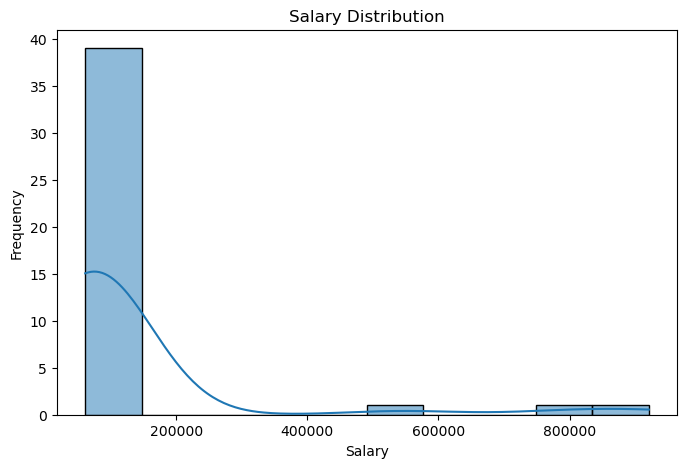

In [53]:
plt.figure(figsize=(8, 5))

sns.histplot(df_clean["Salary"], bins=10, kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

Scatter plot: Age vs Salary

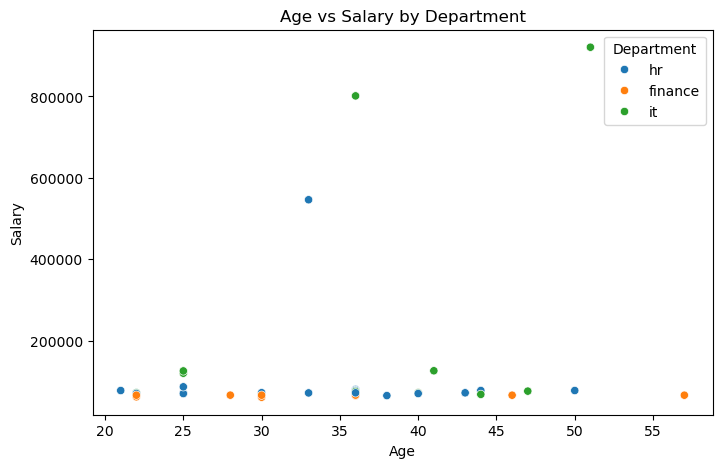

In [54]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="Age",
    y="Salary",
    hue="Department"
)

plt.title("Age vs Salary by Department")
plt.xlabel("Age")
plt.ylabel("Salary")

plt.show()

Line chart: Employee joining trend

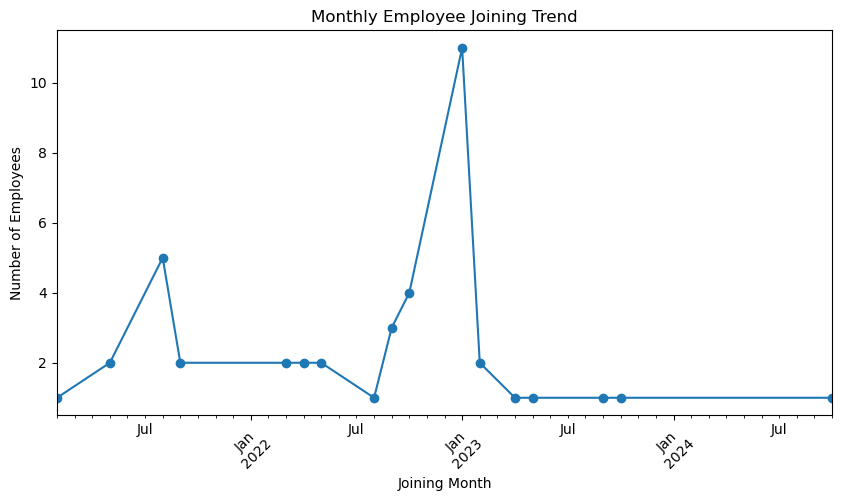

In [55]:
# Extract joining month
df_clean["Join_Month"] = df_clean["Join_Date"].dt.to_period("M")

# Count employees joining each month
monthly_joins = df_clean.groupby("Join_Month").size()

# Plot joining trend
plt.figure(figsize=(10, 5))

monthly_joins.plot(kind="line", marker="o")

plt.title("Monthly Employee Joining Trend")
plt.xlabel("Joining Month")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)

plt.show()

In [56]:
print("Final Dataset Information:")
df_clean.info()

print("\nMissing Values:")
print(df_clean.isnull().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nFinal Dataset Shape:")
print(df_clean.shape)

Final Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Name        42 non-null     object        
 1   Age         42 non-null     float64       
 2   Salary      42 non-null     float64       
 3   Join_Date   42 non-null     datetime64[ns]
 4   Department  42 non-null     object        
 5   Join_Month  42 non-null     period[M]     
dtypes: datetime64[ns](1), float64(2), object(2), period[M](1)
memory usage: 2.1+ KB

Missing Values:
Name          0
Age           0
Salary        0
Join_Date     0
Department    0
Join_Month    0
dtype: int64

Duplicate Rows:
0

Final Dataset Shape:
(42, 6)


In [58]:
print(df_clean)

        Name   Age    Salary  Join_Date Department Join_Month
0        pam  25.0   70200.0 2023-01-15         hr    2023-01
1       jane  36.0   65000.0 2022-08-01    finance    2022-08
2      alice  22.0   71350.0 2021-05-20         hr    2021-05
3        bob  22.0   71841.0 2023-01-15         it    2023-01
4        pam  25.0   71250.0 2023-01-15         hr    2023-01
5       jade  40.0   71841.0 2023-01-15    finance    2023-01
6     joanne  25.0  120000.0 2023-01-16         it    2023-01
7        kim  33.0   71568.0 2021-08-30         hr    2021-08
8        sam  40.0   71841.0 2022-09-05         it    2022-09
9        eli  36.0   80100.0 2022-03-04         hr    2022-03
10       joe  22.0   62000.0 2022-10-09    finance    2022-10
11      anna  36.0   72456.0 2022-04-06         hr    2022-04
12       dan  43.0   71841.0 2023-01-15         hr    2023-01
13     susan  46.0   66000.0 2022-05-03    finance    2022-05
14    pamela  36.0   77421.0 2023-04-02         hr    2023-04
15      